# 3. Exploratory Data Analysis

**Goal:** understand class imbalance, time patterns, amount behavior, feature distributions, and relationships using the cleaned dataset.

**Important:** EDA describes the cleaned data only. It does not fit the GMM, tune thresholds, or change the model's chronological train/validation/test strategy.

## 3.1 Project setup

**Purpose:** load shared configuration and plotting settings.

**Process:** locate the project and import the cleaned-data/report paths.

**Output:** confirmed project and data locations.

In [1]:
import os
import sys
from pathlib import Path

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = Path('/content/drive/MyDrive/card-fraud-triage')
    IN_COLAB = True
except ImportError:
    PROJECT_ROOT = Path.cwd().resolve()
    if not (PROJECT_ROOT / 'src/config.py').is_file():
        PROJECT_ROOT = PROJECT_ROOT.parent
    IN_COLAB = False

if not (PROJECT_ROOT / 'src/config.py').is_file():
    raise FileNotFoundError('Could not locate src/config.py.')
sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import ARTIFACTS, CLEAN_PATH, SEED

np.random.seed(SEED)
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda value: '{:,.4f}'.format(value))

print('Environment:', 'Google Colab' if IN_COLAB else 'Local')
print('Clean data:', CLEAN_PATH)

Environment: Local
Clean data: /Users/yuvrajchandravansi/Desktop/card-fraud-triage/data/processed/creditcard_clean.csv


## 3.2 Load the cleaned dataset

**Purpose:** begin EDA from the artifact produced by the cleaning notebook.

**Process:** read `CLEAN_PATH` and stop if it is empty or unavailable.

**Output:** cleaned row and column counts.

In [2]:
if not CLEAN_PATH.is_file():
    raise FileNotFoundError('Cleaned dataset missing. Run notebooks/cleaning.ipynb first.')
df = pd.read_csv(CLEAN_PATH)
if df.empty:
    raise ValueError('Cleaned dataset contains no rows.')
print('Loaded cleaned dataset: {:,} rows x {} columns'.format(*df.shape))

Loaded cleaned dataset: 283,726 rows x 31 columns


## 3.3 Verify cleaned-data integrity

**Purpose:** ensure the dataset passed to EDA is schema-valid and clean.

**Process:** check required columns, numeric types, missing/infinite values, duplicates, class labels, and negative time/amount values.

**Output:** an integrity table. Any failed check stops execution.

In [3]:
required_columns = ['Time'] + ['V{}'.format(i) for i in range(1, 29)] + ['Amount', 'Class']
missing = df.isna().sum()
infinite = int(np.isinf(df.to_numpy(dtype=float)).sum())
duplicates = int(df.duplicated().sum())
negative_amount = int((df['Amount'] < 0).sum())
negative_time = int((df['Time'] < 0).sum())

integrity = pd.DataFrame([
    ('Required schema', set(required_columns).issubset(df.columns), '31 required columns'),
    ('All columns numeric', all(pd.api.types.is_numeric_dtype(df[column]) for column in df.columns), 'No text columns'),
    ('No missing values', int(missing.sum()) == 0, '{} cells'.format(int(missing.sum()))),
    ('No infinite values', infinite == 0, '{} values'.format(infinite)),
    ('No duplicate rows', duplicates == 0, '{} rows'.format(duplicates)),
    ('Valid Class labels', set(df['Class'].unique()).issubset({0, 1}), '{} labels'.format(sorted(df['Class'].unique()))),
    ('Both classes present', set(df['Class']) == {0, 1}, 'Legitimate and fraud'),
    ('No negative Amount', negative_amount == 0, '{} rows'.format(negative_amount)),
    ('No negative Time', negative_time == 0, '{} rows'.format(negative_time)),
], columns=['check', 'passed', 'detail'])
display(integrity)
if not integrity['passed'].all():
    raise ValueError('Cleaned-data integrity checks failed.')
print('All integrity checks passed.')

,check,passed,detail
0,Required schema,True,31 required columns
1,All columns numeric,True,No text columns
2,No missing values,True,0 cells
3,No infinite values,True,0 values
4,No duplicate rows,True,0 rows
5,Valid Class labels,True,"[np.int64(0), np.int64(1)] labels"
6,Both classes present,True,Legitimate and fraud
7,No negative Amount,True,0 rows
8,No negative Time,True,0 rows


All integrity checks passed.


## 3.4 Confirm the cleaning report

**Purpose:** connect EDA to the recorded cleaning decisions.

**Process:** compare report shapes, removal totals, duplicate counts, and fraud counts with the loaded CSV.

**Output:** a small cleaning-context summary.

In [4]:
clean_report_path = Path(ARTIFACTS) / 'clean_report.json'
if not clean_report_path.is_file():
    raise FileNotFoundError('Cleaning report missing. Run notebooks/cleaning.ipynb first.')
report = json.loads(clean_report_path.read_text(encoding='utf-8'))

assert report['clean_shape'] == list(df.shape)
assert report['raw_shape'][1] == df.shape[1]
assert report['rows_removed']['total'] == report['raw_shape'][0] - df.shape[0]
assert report['rows_removed']['exact_duplicates'] == report['duplicate_analysis']['duplicate_rows_labelled_fraud'] + report['duplicate_analysis']['duplicate_rows_labelled_legitimate']
assert report['after_cleaning']['Fraud transactions'] == int((df['Class'] == 1).sum())

context = pd.Series({
    'Raw rows': report['raw_shape'][0],
    'Clean rows': report['clean_shape'][0],
    'Rows removed': report['rows_removed']['total'],
    'Duplicate rows removed': report['rows_removed']['exact_duplicates'],
    'Missing/infinite rows removed': report['rows_removed']['missing_or_infinite_values'],
}, name='Cleaning context')
display(context.to_frame())

,Cleaning context
Raw rows,284807
Clean rows,283726
Rows removed,1081
Duplicate rows removed,1081
Missing/infinite rows removed,0


## 3.5 Review descriptive statistics

**Purpose:** understand scale and spread across `Time`, `V1`–`V28`, and `Amount`.

**Process:** calculate count, mean, standard deviation, quartiles, and skewness.

**Output:** a compact feature-profile table.

In [5]:
feature_columns = ['Time'] + ['V{}'.format(i) for i in range(1, 29)] + ['Amount']
statistics = df[feature_columns].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]).T
statistics['IQR'] = statistics['75%'] - statistics['25%']
statistics['skewness'] = df[feature_columns].skew()
display(statistics)

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max,IQR,skewness
Time,"283,726.0000","94,811.0776","47,481.0479",0.0000,"54,204.7500","84,692.5000","139,298.0000","157,631.0000","164,138.7500","170,557.7500","172,792.0000","85,093.2500",-0.0356
V1,"283,726.0000",0.0059,1.9480,-56.4075,-0.9160,0.0204,1.3161,2.0158,2.0814,2.2373,2.4549,2.2320,-3.2733
V2,"283,726.0000",-0.0041,1.6467,-72.7157,-0.6003,0.0639,0.8003,1.3195,1.7961,3.7663,22.0577,1.4006,-4.6952
V3,"283,726.0000",0.0016,1.5087,-48.3256,-0.8897,0.1800,1.0270,1.6756,2.0621,2.7259,9.3826,1.9166,-2.1520
V4,"283,726.0000",-0.0030,1.4142,-5.6832,-0.8501,-0.0222,0.7396,1.4792,2.5566,4.2444,16.8753,1.5898,0.6715
V5,"283,726.0000",0.0018,1.3770,-113.7433,-0.6898,-0.0535,0.6122,1.4069,2.0997,3.4270,34.8017,1.3020,-2.4141
V6,"283,726.0000",-0.0011,1.3319,-26.1605,-0.7690,-0.2752,0.3968,1.5070,3.1594,4.1996,73.3016,1.1658,1.8299
V7,"283,726.0000",0.0018,1.2277,-43.5572,-0.5525,0.0409,0.5705,1.0390,1.4071,2.6800,120.5895,1.1230,2.8903
V8,"283,726.0000",-0.0009,1.1791,-73.2167,-0.2088,0.0219,0.3257,0.7652,1.0423,2.0442,20.0072,0.5345,-8.3110
V9,"283,726.0000",-0.0016,1.0955,-13.4341,-0.6442,-0.0526,0.5960,1.3001,1.7786,2.9763,15.5950,1.2402,0.5377


## 3.6 Analyze class imbalance

**Purpose:** quantify how uncommon fraud is in the cleaned dataset.

**Process:** compare absolute counts and percentages and print the imbalance ratio.

**Output:** a class table and a pair of labeled charts.

,transactions,percentage
Legitimate (0),283253,99.8333
Fraud (1),473,0.1667


Fraud prevalence: 0.1667%
Legitimate-to-fraud ratio: 598.8:1


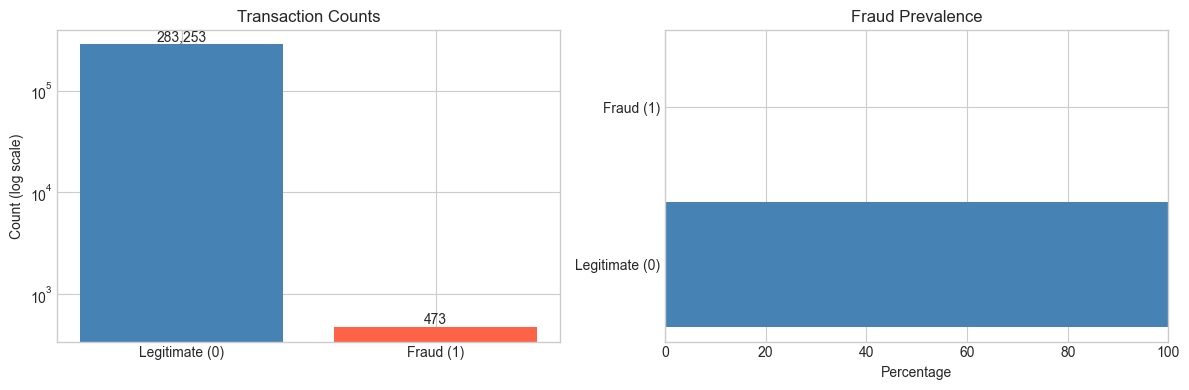

In [6]:
class_counts = df['Class'].value_counts().reindex([0, 1], fill_value=0)
legitimate_count = int(class_counts.loc[0])
fraud_count = int(class_counts.loc[1])
total_count = len(df)

class_summary = pd.DataFrame({
    'transactions': [legitimate_count, fraud_count],
    'percentage': [legitimate_count / total_count * 100, fraud_count / total_count * 100],
}, index=['Legitimate (0)', 'Fraud (1)'])
display(class_summary)
print('Fraud prevalence: {:.4f}%'.format(fraud_count / total_count * 100))
print('Legitimate-to-fraud ratio: {:.1f}:1'.format(legitimate_count / fraud_count))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(class_summary.index, class_summary['transactions'], color=['steelblue', 'tomato'])
axes[0].set_title('Transaction Counts')
axes[0].set_yscale('log')
axes[0].set_ylabel('Count (log scale)')
for position, value in enumerate(class_summary['transactions']):
    axes[0].text(position, value, '{:,}'.format(value), ha='center', va='bottom')

axes[1].barh(class_summary.index, class_summary['percentage'], color=['steelblue', 'tomato'])
axes[1].set_title('Fraud Prevalence')
axes[1].set_xlabel('Percentage')
axes[1].set_xlim(0, 100)
plt.tight_layout()
plt.show()

## 3.7 Analyze transaction volume over time

**Purpose:** check whether cleaned activity is evenly distributed across the dataset timeline.

**Process:** convert elapsed seconds to hours, place transactions into hourly bins, and plot volume by class.

**Output:** a one-dimensional fraud/legitimate activity timeline.

/var/folders/ps/7lkn6rwn7ng3w5rj5vfh7h4r0000gn/T/ipykernel_34480/1936410106.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  volume = timeline.groupby(['hour_bin', 'Class']).size().unstack(fill_value=0)


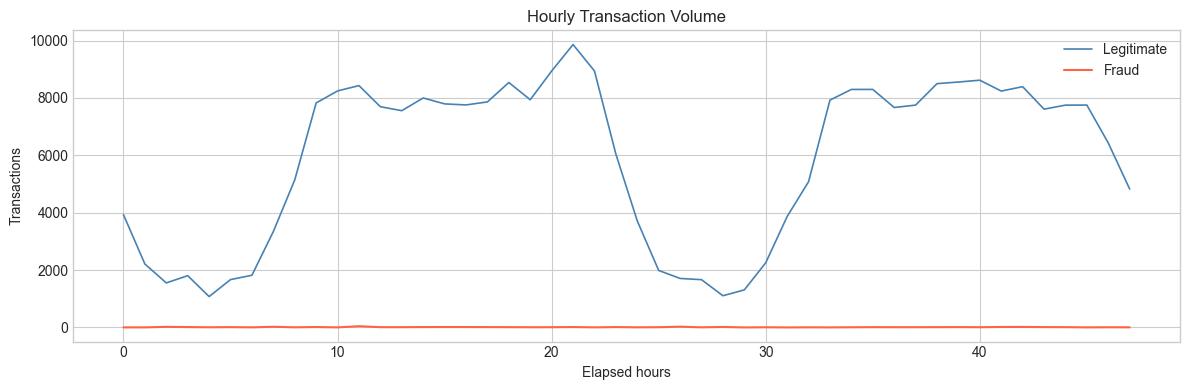

In [7]:
hours = (df['Time'] / 3600).rename('elapsed_hours')
timeline = pd.DataFrame({'elapsed_hours': hours, 'Class': df['Class']})
bins = np.arange(0, timeline['elapsed_hours'].max() + 1, 1)
timeline['hour_bin'] = pd.cut(timeline['elapsed_hours'], bins=bins, right=False)
volume = timeline.groupby(['hour_bin', 'Class']).size().unstack(fill_value=0)
centers = np.array([interval.left for interval in volume.index])

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(centers, volume.get(0, 0).values, label='Legitimate', color='steelblue', linewidth=1.2)
ax.plot(centers, volume.get(1, 0).values, label='Fraud', color='tomato', linewidth=1.5)
ax.set_title('Hourly Transaction Volume')
ax.set_xlabel('Elapsed hours')
ax.set_ylabel('Transactions')
ax.legend()
plt.tight_layout()
plt.show()

## 3.8 Compare fraud and legitimate amounts

**Purpose:** see whether transaction amount separates fraud and legitimate behavior.

**Process:** use descriptive statistics and two side-by-side box plots.

**Output:** amount summaries and a compact visual comparison.

,Legitimate (0),Fraud (1)
count,"283,253.0000",473.0000
mean,88.4136,123.8719
std,250.3790,260.2110
min,0.0000,0.0000
25%,5.6700,1.0000
50%,22.0000,9.8200
75%,77.4600,105.8900
90%,203.0000,348.6520
95%,365.0000,655.8200
99%,"1,018.0576","1,364.1368"


/var/folders/ps/7lkn6rwn7ng3w5rj5vfh7h4r0000gn/T/ipykernel_34480/2812002625.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot([df.loc[df['Class'] == 0, 'Amount'], df.loc[df['Class'] == 1, 'Amount']], labels=['Legitimate', 'Fraud'], showfliers=False)
/var/folders/ps/7lkn6rwn7ng3w5rj5vfh7h4r0000gn/T/ipykernel_34480/2812002625.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot([df.loc[df['Class'] == 0, 'Amount'], df.loc[df['Class'] == 1, 'Amount']], labels=['Legitimate', 'Fraud'], showfliers=True)


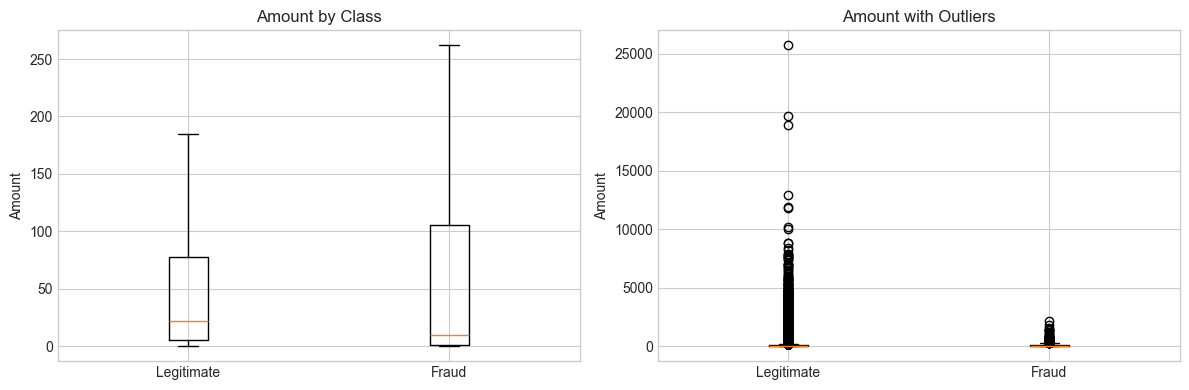

In [8]:
amount_summary = df.groupby('Class')['Amount'].describe(percentiles=[0.25, 0.5, 0.75, 0.90, 0.95, 0.99]).T
amount_summary.columns = ['Legitimate (0)', 'Fraud (1)']
display(amount_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].boxplot([df.loc[df['Class'] == 0, 'Amount'], df.loc[df['Class'] == 1, 'Amount']], labels=['Legitimate', 'Fraud'], showfliers=False)
axes[0].set_title('Amount by Class')
axes[0].set_ylabel('Amount')

axes[1].boxplot([df.loc[df['Class'] == 0, 'Amount'], df.loc[df['Class'] == 1, 'Amount']], labels=['Legitimate', 'Fraud'], showfliers=True)
axes[1].set_title('Amount with Outliers')
axes[1].set_ylabel('Amount')
plt.tight_layout()
plt.show()

## 3.9 Inspect amount distribution

**Purpose:** identify the heavy-tailed shape of `Amount`.

**Process:** plot separate linear and logarithmic histograms for the cleaned dataset.

**Output:** distribution plots. No amount values are transformed.

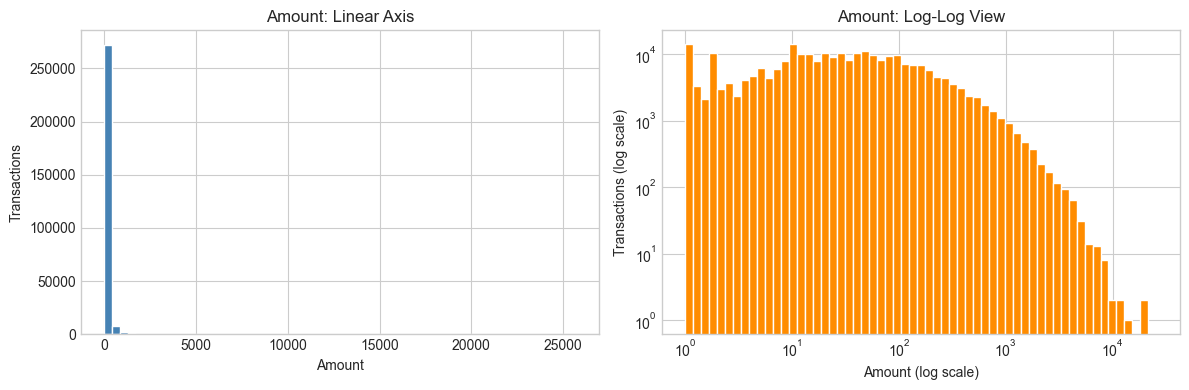

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df['Amount'], bins=60, color='steelblue', edgecolor='white')
axes[0].set_title('Amount: Linear Axis')
axes[0].set_xlabel('Amount')
axes[0].set_ylabel('Transactions')

axes[1].hist(df['Amount'], bins=np.logspace(0, np.log10(df['Amount'].max()), 60), color='darkorange', edgecolor='white')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_title('Amount: Log-Log View')
axes[1].set_xlabel('Amount (log scale)')
axes[1].set_ylabel('Transactions (log scale)')
plt.tight_layout()
plt.show()

## 3.10 Rank feature associations with fraud

**Purpose:** identify the strongest simple associations worth discussing before GMM modeling.

**Process:** calculate absolute Spearman correlation between each numeric model feature and `Class`.

**Output:** a top-15 table and bar chart. Correlation does not imply causation or model quality.

,spearman_correlation,absolute_correlation
V14,-0.0632,0.0632
V4,0.0617,0.0617
V12,-0.0614,0.0614
V11,0.0586,0.0586
V10,-0.0580,0.0580
V3,-0.0577,0.0577
V2,0.0494,0.0494
V16,-0.0483,0.0483
V9,-0.0482,0.0482
V7,-0.0466,0.0466


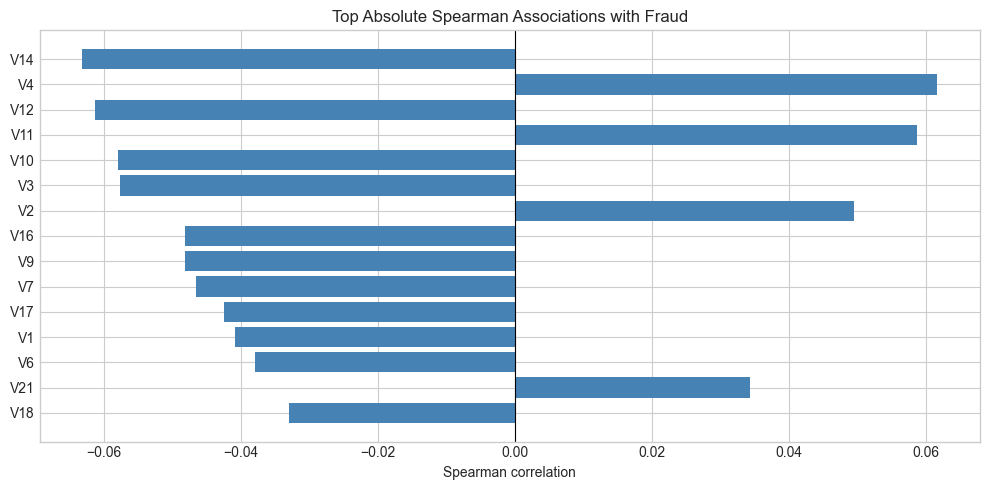

In [10]:
association_features = ['V{}'.format(i) for i in range(1, 29)] + ['Amount']
associations = df[association_features + ['Class']].corr(method='spearman')['Class'].drop('Class')
association_table = pd.DataFrame({
    'spearman_correlation': associations,
    'absolute_correlation': associations.abs(),
}).sort_values('absolute_correlation', ascending=False)
top_associations = association_table.head(15)
display(top_associations)

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top_associations.index[::-1], top_associations['spearman_correlation'][::-1], color='steelblue')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Top Absolute Spearman Associations with Fraud')
ax.set_xlabel('Spearman correlation')
plt.tight_layout()
plt.show()

## 3.11 Check PCA-feature correlations

**Purpose:** detect redundant linear relationships among the anonymized PCA features.

**Process:** compute a Pearson correlation matrix for `V1`–`V28` and show only the strongest observed relationships.

**Output:** a full correlation heatmap and a concise strongest-pair table.

,feature_1,feature_2,correlation
0,V8,V21,0.0189
1,V1,V27,-0.0157
2,V27,V28,-0.0140
3,V7,V10,-0.0136
4,V14,V17,-0.0136
5,V12,V17,-0.0129
6,V9,V10,-0.0126
7,V3,V7,-0.0117
8,V10,V27,0.0108
9,V12,V14,-0.0100


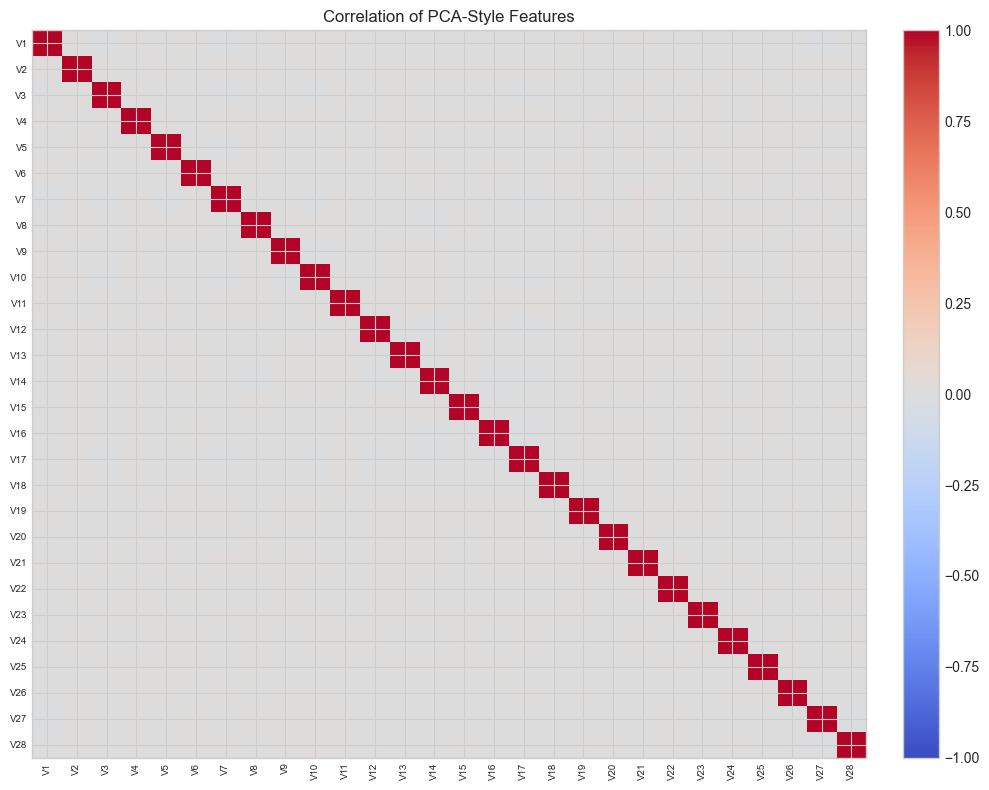

In [11]:
pca_features = ['V{}'.format(i) for i in range(1, 29)]
pca_correlation = df[pca_features].corr()

upper = pca_correlation.where(np.triu(np.ones(pca_correlation.shape), k=1).astype(bool))
pairs = upper.stack().rename('correlation').sort_values(key=np.abs, ascending=False)
strongest_pairs = pd.DataFrame({
    'feature_1': [pair[0] for pair in pairs.index[:10]],
    'feature_2': [pair[1] for pair in pairs.index[:10]],
    'correlation': pairs.values[:10],
})
display(strongest_pairs)

fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(pca_correlation, vmin=-1, vmax=1, cmap='coolwarm', aspect='auto')
ax.set_xticks(range(len(pca_features)), pca_features, rotation=90, fontsize=7)
ax.set_yticks(range(len(pca_features)), pca_features, fontsize=7)
ax.set_title('Correlation of PCA-Style Features')
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

## 3.12 Export the EDA report

**Purpose:** preserve the principal descriptive findings for documentation.

**Process:** save class counts, fraud prevalence, amount percentiles, strongest associations, and cleaning context as JSON.

**Output:** `artifacts/eda_report.json`.

In [12]:
def json_safe(value):
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, (np.ndarray, list, tuple)):
        return [json_safe(item) for item in value]
    if isinstance(value, dict):
        return {str(key): json_safe(item) for key, item in value.items()}
    return value

eda_report = {
    'dataset_shape': [int(df.shape[0]), int(df.shape[1])],
    'class_counts': {str(key): int(value) for key, value in class_counts.items()},
    'fraud_prevalence': float(fraud_count / total_count),
    'legitimate_to_fraud_ratio': float(legitimate_count / fraud_count),
    'amount_quantiles': df['Amount'].quantile([0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 0.999]).to_dict(),
    'top_feature_associations': [
        {
            'feature': feature,
            'spearman_correlation': float(row['spearman_correlation']),
            'absolute_correlation': float(row['absolute_correlation']),
        }
        for feature, row in top_associations.iterrows()
    ],
    'cleaning_context': {
        'raw_rows': int(report['raw_shape'][0]),
        'clean_rows': int(report['clean_shape'][0]),
        'rows_removed': int(report['rows_removed']['total']),
        'frauds_removed_by_cleaning': int(report['before_cleaning']['Fraud transactions'] - report['after_cleaning']['Fraud transactions']),
    },
}
eda_report_path = Path(ARTIFACTS) / 'eda_report.json'
eda_report_path.write_text(json.dumps(json_safe(eda_report), indent=2) + chr(10), encoding='utf-8')
print('Saved EDA report:', eda_report_path)

Saved EDA report: /Users/yuvrajchandravansi/Desktop/card-fraud-triage/artifacts/eda_report.json


## 3.13 Findings and next step

- The cleaned dataset is heavily imbalanced: legitimate transactions dominate.
- `Amount` is strongly right-skewed and may contain a few very large values.
- Fraud activity varies over the elapsed-time timeline.
- Individual PCA features have different strengths of association with `Class`.
- PCA features are largely decorrelated, consistent with their source transformation.
- These findings explain later model choices, but do not prove a classifier.

The next step is the GMM baseline, where the saved scaler and GMM must be fit only on legitimate training rows. The chronological split and validation-only threshold must remain unchanged.